## Segundo paso: análisar los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [134]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt

In [135]:
result_path = "./results/minimal_v5/"
# path_minimal = "./dataset_minimal/"

In [136]:
def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attack"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=30, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attack"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Dataset

In [137]:
# Cargar el DataFrame
df_cdcp = pd.read_pickle(result_path + "CDCP_Minimal_Grafo.pkl")
df_aaec = pd.read_pickle(result_path + "AAEC_Minimal_Grafo.pkl")
df_argpt = pd.read_pickle(result_path + "ArGPT_Minimal_Grafo.pkl")
df_mtc = pd.read_pickle(result_path + "MTC_Minimal_Grafo.pkl")
df_aasd = pd.read_pickle(result_path + "AASD_Minimal_Grafo.pkl")

In [138]:
df = df_cdcp
df

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
0,CDCP_00194,3,minimalist_labels labels_relation source...,"(CDCP_00194_0, CDCP_00194_1, CDCP_00194_2)",3,1,2,1
1,CDCP_00195,3,minimalist_labels labels_relation source...,"(CDCP_00195_0, CDCP_00195_1, CDCP_00195_2)",3,2,1,0
2,CDCP_00196,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00196_0, CDCP_00196_1, CDCP_00196_2, CDC...",5,0,5,5
3,CDCP_00197,4,minimalist_labels labels_relation source...,"(CDCP_00197_0, CDCP_00197_1, CDCP_00197_2, CDC...",4,1,3,2
4,CDCP_00198,4,minimalist_labels labels_relation source...,"(CDCP_00198_0, CDCP_00198_1, CDCP_00198_2, CDC...",4,1,3,2
...,...,...,...,...,...,...,...,...
725,CDCP_01411,15,minimalist_labels labels_relation sourc...,"(CDCP_01411_0, CDCP_01411_1, CDCP_01411_2, CDC...",15,8,7,3
726,CDCP_01412,15,minimalist_labels labels_relation sourc...,"(CDCP_01412_0, CDCP_01412_1, CDCP_01412_2, CDC...",15,7,8,5
727,CDCP_01414,12,minimalist_labels labels_relation source...,"(CDCP_01414_0, CDCP_01414_1, CDCP_01414_2, CDC...",12,2,10,8
728,CDCP_01417,18,minimalist_labels labels_relation sourc...,"(CDCP_01417_0, CDCP_01417_1, CDCP_01417_2, CDC...",18,4,14,11


In [139]:
id_text_busca = "CDCP_00194"
columna = "text_id"
result = df[df[columna] == id_text_busca]
result

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
0,CDCP_00194,3,minimalist_labels labels_relation source...,"(CDCP_00194_0, CDCP_00194_1, CDCP_00194_2)",3,1,2,1


In [140]:
result_info = result.iloc[0]
result_info["info"]
# print(tabulate(result_info["info"].reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))

,minimalist_labels,labels_relation,source_id,label_component_source,minimal_label_component_source,target_id,label_component_target,minimal_label_component_target
0,support,reason,CDCP_00194_1,value,Premise,CDCP_00194_2,policy,MajorClaim


### Caracteristicas de grafo

In [154]:
# Numeros de nodos y componentes
df_comparacion = df[
    (df["n_comp"] == 1)
]
conteo = df_comparacion.groupby("n_comp").size()
lista = conteo.to_dict()
print(df_comparacion.shape)
print("Lista de componentes: ",lista)
df_comparacion

(91, 8)
Lista de componentes:  {1: 91}


,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
1,CDCP_00195,3,minimalist_labels labels_relation source...,"(CDCP_00195_0, CDCP_00195_1, CDCP_00195_2)",3,2,1,0
6,CDCP_00200,2,minimalist_labels labels_relation source...,"(CDCP_00200_0, CDCP_00200_1)",2,1,1,0
8,CDCP_00203,2,minimalist_labels labels_relation source...,"(CDCP_00203_0, CDCP_00203_1)",2,1,1,0
9,CDCP_00204,2,minimalist_labels labels_relation source...,"(CDCP_00204_0, CDCP_00204_1)",2,1,1,0
10,CDCP_00205,2,minimalist_labels labels_relation source...,"(CDCP_00205_0, CDCP_00205_1)",2,1,1,0
...,...,...,...,...,...,...,...,...
651,CDCP_01289,3,minimalist_labels labels_relation source...,"(CDCP_01289_0, CDCP_01289_1, CDCP_01289_2)",3,2,1,0
661,CDCP_01303,3,minimalist_labels labels_relation source...,"(CDCP_01303_0, CDCP_01303_1, CDCP_01303_2)",3,2,1,0
677,CDCP_01329,4,minimalist_labels labels_relation source...,"(CDCP_01329_0, CDCP_01329_1, CDCP_01329_2, CDC...",4,4,1,0
681,CDCP_01337,4,minimalist_labels labels_relation source...,"(CDCP_01337_0, CDCP_01337_1, CDCP_01337_2, CDC...",4,4,1,0


In [155]:
# Caracteristicas del grafo
acyclic = "acyclic"
cycles = "cycles"
is_tree = "tree"
is_arborescence = "arborescence"
nodes_roots = "n_roots"

# Aciclico e ciclos
df_comparacion[acyclic] = df_comparacion["graph"].apply(lambda graph: nx.is_directed_acyclic_graph(graph))
df_comparacion[cycles] = df_comparacion["graph"].apply(lambda graph: list(nx.simple_cycles(graph)))

# Arbol
df_comparacion[is_tree] = df_comparacion["graph"].apply(lambda graph: nx.is_tree(graph))
df_comparacion[is_arborescence] = df_comparacion["graph"].apply(lambda graph: nx.is_arborescence(graph))

#Numero de nodos raiz
df_comparacion[nodes_roots] = df_comparacion["graph"].apply(lambda G: sum(1 for _, grado in G.in_degree() if grado == 0))

df_comparacion

/tmp/ipykernel_32959/2155539133.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_comparacion[acyclic] = df_comparacion["graph"].apply(lambda graph: nx.is_directed_acyclic_graph(graph))
/tmp/ipykernel_32959/2155539133.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_comparacion[cycles] = df_comparacion["graph"].apply(lambda graph: list(nx.simple_cycles(graph)))
/tmp/ipykernel_32959/2155539133.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try u

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates,acyclic,cycles,tree,arborescence,n_roots
1,CDCP_00195,3,minimalist_labels labels_relation source...,"(CDCP_00195_0, CDCP_00195_1, CDCP_00195_2)",3,2,1,0,True,[],True,True,1
6,CDCP_00200,2,minimalist_labels labels_relation source...,"(CDCP_00200_0, CDCP_00200_1)",2,1,1,0,True,[],True,True,1
8,CDCP_00203,2,minimalist_labels labels_relation source...,"(CDCP_00203_0, CDCP_00203_1)",2,1,1,0,True,[],True,True,1
9,CDCP_00204,2,minimalist_labels labels_relation source...,"(CDCP_00204_0, CDCP_00204_1)",2,1,1,0,True,[],True,True,1
10,CDCP_00205,2,minimalist_labels labels_relation source...,"(CDCP_00205_0, CDCP_00205_1)",2,1,1,0,True,[],True,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
651,CDCP_01289,3,minimalist_labels labels_relation source...,"(CDCP_01289_0, CDCP_01289_1, CDCP_01289_2)",3,2,1,0,True,[],True,True,1
661,CDCP_01303,3,minimalist_labels labels_relation source...,"(CDCP_01303_0, CDCP_01303_1, CDCP_01303_2)",3,2,1,0,True,[],True,True,1
677,CDCP_01329,4,minimalist_labels labels_relation source...,"(CDCP_01329_0, CDCP_01329_1, CDCP_01329_2, CDC...",4,4,1,0,True,[],False,False,2
681,CDCP_01337,4,minimalist_labels labels_relation source...,"(CDCP_01337_0, CDCP_01337_1, CDCP_01337_2, CDC...",4,4,1,0,True,[],False,False,1


In [161]:
# df_acyclic = df_comparacion[df_comparacion[acyclic].apply(lambda x: x == True)]
# df_acyclic.shape
# df_tree = df_comparacion[df_comparacion[is_tree].apply(lambda x: x == True)]
# df_tree.shape
df_n_root = df_comparacion[df_comparacion[nodes_roots].apply(lambda x: x != 1)]
df_n_root

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates,acyclic,cycles,tree,arborescence,n_roots
31,CDCP_00240,5,minimalist_labels labels_relation source...,"(CDCP_00240_0, CDCP_00240_1, CDCP_00240_2, CDC...",5,5,1,0,True,[],False,False,2
62,CDCP_00344,4,minimalist_labels labels_relation source...,"(CDCP_00344_0, CDCP_00344_1, CDCP_00344_2, CDC...",4,4,1,0,True,[],False,False,2
109,CDCP_00400,7,minimalist_labels labels_relation source...,"(CDCP_00400_0, CDCP_00400_1, CDCP_00400_2, CDC...",7,7,1,0,True,[],False,False,2
114,CDCP_00406,5,minimalist_labels labels_relation source...,"(CDCP_00406_0, CDCP_00406_1, CDCP_00406_2, CDC...",5,4,1,0,True,[],True,False,2
273,CDCP_00649,4,minimalist_labels labels_relation source...,"(CDCP_00649_0, CDCP_00649_1, CDCP_00649_2, CDC...",4,4,1,0,True,[],False,False,2
338,CDCP_00762,5,minimalist_labels labels_relation source...,"(CDCP_00762_0, CDCP_00762_1, CDCP_00762_2, CDC...",5,4,1,0,True,[],True,False,2
339,CDCP_00763,3,minimalist_labels labels_relation source...,"(CDCP_00763_0, CDCP_00763_1, CDCP_00763_2)",3,2,1,0,True,[],True,False,2
562,CDCP_01147,3,minimalist_labels labels_relation source...,"(CDCP_01147_0, CDCP_01147_1, CDCP_01147_2)",3,2,1,0,True,[],True,False,2
647,CDCP_01283,6,minimalist_labels labels_relation source...,"(CDCP_01283_0, CDCP_01283_1, CDCP_01283_2, CDC...",6,6,1,0,True,[],False,False,3
677,CDCP_01329,4,minimalist_labels labels_relation source...,"(CDCP_01329_0, CDCP_01329_1, CDCP_01329_2, CDC...",4,4,1,0,True,[],False,False,2


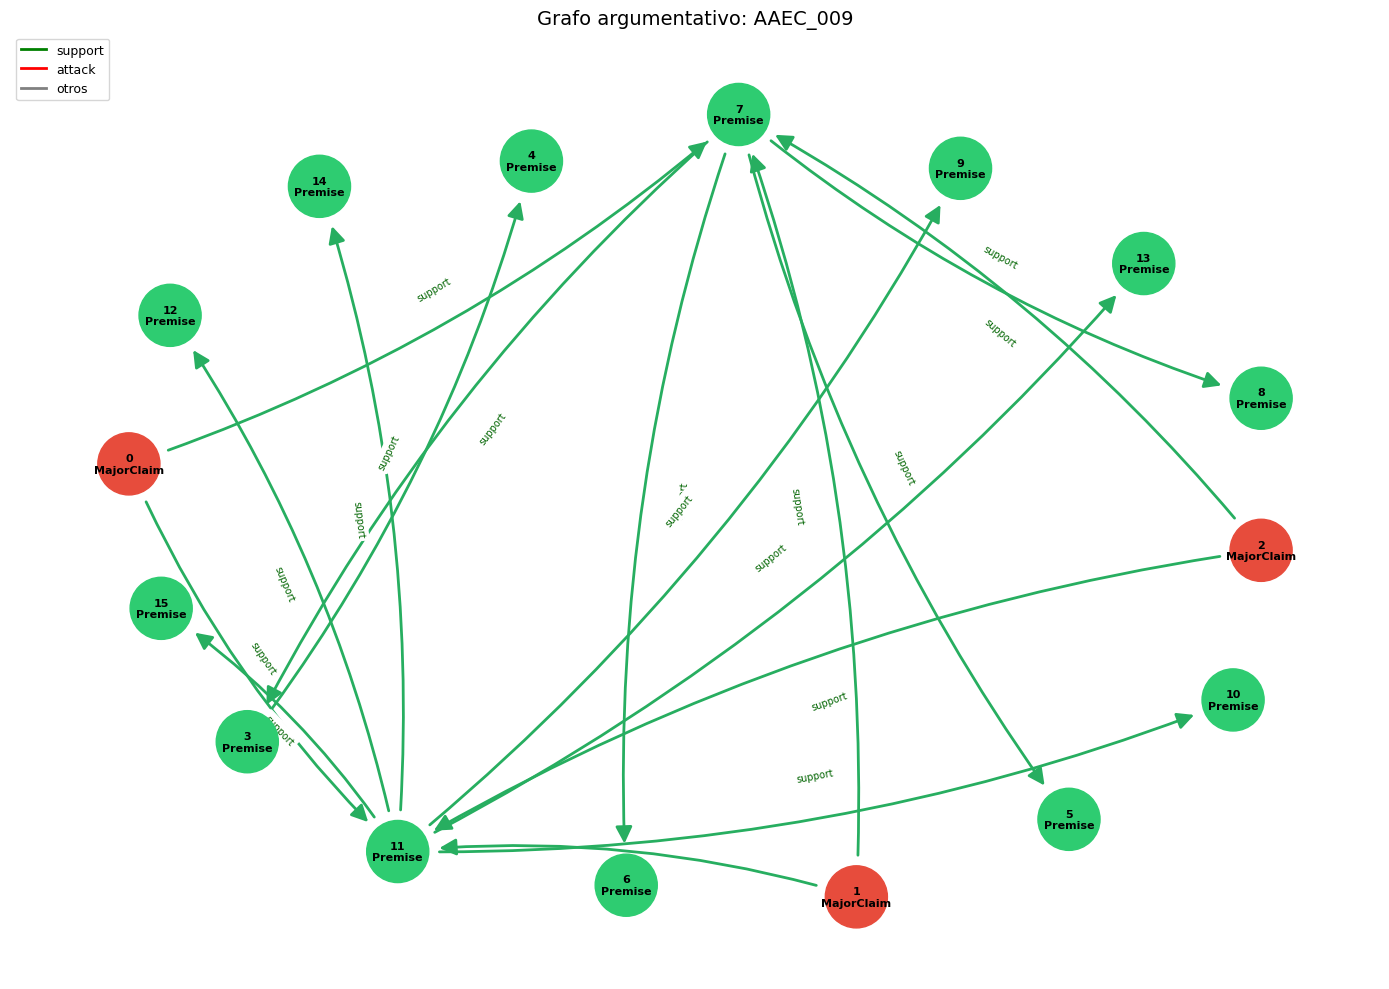

In [142]:
plot_grafo(id_text_busca, result_info["graph"])

## Resulatado de la Dataframe Summary minimal

In [133]:
df_resultados = pd.read_pickle(result_path + "dataframe_summary.pkl")
df_resultados
print(tabulate(df_resultados, headers='keys', tablefmt='rounded_outline', showindex=True))

╭──────────┬──────────────────┬────────────┬───────────────────┬──────────┬────────────┬──────────────────────┬──────────╮
│          │   total_text_arg │   isolados │ subgrafos         │   conexo │   aciclico │ nos_raiz             │   arvore │
├──────────┼──────────────────┼────────────┼───────────────────┼──────────┼────────────┼──────────────────────┼──────────┤
│ CDCP     │              730 │        616 │ 2: 19, 3: 3, 4: 1 │       91 │         91 │ 1: 81, 2: 9, 3: 1    │       74 │
│ AAEC     │              402 │          2 │                   │      400 │        400 │ 1: 71, 2: 311, 3: 18 │       71 │
│ ArGPT    │              172 │         44 │ 2: 21, 3: 6, 4: 1 │      100 │          6 │ 0: 14, 1: 17, 2: 28,
3: 23, 4: 10, 5: 7,
6: 1                      │        1 │
│ MTC      │              112 │          0 │                   │      112 │        112 │ 1: 112               │      112 │
│ AASD     │               60 │          0 │                   │       60 │         60 │ 1: 6